# Install Dependecies

In [1]:
%%capture
%pip install -q "transformers>=5,<6"
%pip install matplotlib
%pip install ipynbname
%pip install datasets
%pip install -U "ipywidgets>=8"
%pip install -q "evaluate>=0.4,<1"

In [2]:
%%capture
%pip install torch torchvision --index-url https://download.pytorch.org/whl/cu130
%pip install ipykernel

# Imports

In [3]:
import numpy as np
import pandas as pd
import random
import torch
import transformers
import matplotlib.pyplot as plt
from collections import Counter, defaultdict, OrderedDict
from functools import partial
from datasets import load_dataset
from torch import nn
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR
from torch.utils.data import DataLoader
from tqdm.std import tqdm
from transformers import AutoTokenizer
from transformers import AutoModelForQuestionAnswering
from transformers import get_linear_schedule_with_warmup
from sklearn.metrics import classification_report
from sklearn.metrics import precision_recall_fscore_support
import ipynbname
from pathlib import Path
from evaluate import load as load_metric

In [4]:
ROOT_DIR = ipynbname.path().parent
ROOT_DIR = Path(ROOT_DIR)
print(ROOT_DIR)

/home/tlvj/msc_datalogi/2_semester/nlp/msc-nlp-2026/project_notebooks


# Import datasets

In [5]:
dataset = load_dataset("coastalcph/tydi_xor_rc")
df_train = dataset["train"].to_pandas()
df_val = dataset["validation"].to_pandas()

# Preprocessing

In [6]:
LANGUAGES = ["ar", "ko", "te"]

In [7]:
# select languages
df_train = df_train[df_train["lang"].isin(LANGUAGES)].copy()
df_val = df_val[df_val["lang"].isin(LANGUAGES)].copy()

# Tokeniser

In [8]:
tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")

# 6 Week 40-41: Integrated Multilingual QA
1. Fine-tune one multilingual Transformer QA model that receives a non-English
question and English context and predicts either (i) start and end positions of
an English answer span or (ii) no answer. Train a single joint model on Arabic,
Korean and Telugu unless you have a clearly motivated alternative. State how
the model scores no answer, then choose the no-answer threshold defined in
Section 1 using validation data only.

2. Evaluate the integrated model according to Section 1. Compare its span predictions with the Week 37 sequence labeller and its abstention decisions with the
Week 39 answerability classifiers. Analyse at least ten validation errors, using a
linguistically or task-motivated error taxonomy rather than only grouping cases
as short/medium/long inputs or low/medium/high model confidence. Include
examples from all three languages.

In [9]:
# nlp_project_w36.ipynb
def evaluate_answerability(df, pred_column):
    rows = []
    for lang in ["all"] + LANGUAGES:
        part = df if lang == "all" else df[df["lang"] == lang]
        report = classification_report(part["answerable"], part[pred_column], labels=[True, False],
                                       target_names=["answerable", "unanswerable"], zero_division=0, output_dict=True)
        rows.append({
            "lang": lang,
            "n": len(part),
            "n_unans": int(report["unanswerable"]["support"]),
            "ans_p": report["answerable"]["precision"],
            "ans_r": report["answerable"]["recall"],
            "ans_f1": report["answerable"]["f1-score"],
            "unans_p": report["unanswerable"]["precision"],
            "unans_r": report["unanswerable"]["recall"],
            "unans_f1": report["unanswerable"]["f1-score"],
            "macro_f1": report["macro avg"]["f1-score"],
            "accuracy": report["accuracy"],
        })
    return pd.DataFrame(rows).round(3)

In [10]:
# nlp_project_w37.ipynb
def tokenize_with_offsets(text):
    encoding = tokenizer(text, return_offsets_mapping=True, add_special_tokens=False)
    tokens = tokenizer.convert_ids_to_tokens(encoding["input_ids"])
    offsets = [tuple(offset) for offset in encoding["offset_mapping"]]
    return tokens, offsets

In [11]:
# lab_2.ipynb
def character_span_to_bio(context, answer_start=None, answer_text=""):
    tokens, offsets = tokenize_with_offsets(context)
    labels = ["O"] * len(tokens)

    if answer_start is None or answer_text == "":
        return tokens, offsets, labels

    answer_end = answer_start + len(answer_text)
    if context[answer_start:answer_end] != answer_text:
        raise ValueError("The supplied answer text does not match the character span")

    covered = [
        index
        for index, (start, end) in enumerate(offsets)
        if start < answer_end and end > answer_start
    ]
    if not covered:
        raise ValueError("The answer does not overlap any token")

    labels[covered[0]] = "B-ANS"
    for index in covered[1:]:
        labels[index] = "I-ANS"
    return tokens, offsets, labels

In [12]:
# nlp_project_w37.ipynb
def row_to_bio(row):
    if not row["answerable"]:
        return character_span_to_bio(row["context"])
    return character_span_to_bio(row["context"], row["answer_start"], row["answer"])

In [13]:
# nlp_project_w37.ipynb
def evaluate_spans(df, pred_column):
    rows = []
    for lang in ["all"] + LANGUAGES:
        part = df if lang == "all" else df[df["lang"] == lang]
        gold_tokens = [label != "O" for labels in part["labels"] for label in labels]
        pred_tokens = [label != "O" for labels in part[pred_column] for label in labels]
        precision, recall, f1, _ = precision_recall_fscore_support(gold_tokens, pred_tokens, average="binary", zero_division=0)
        exact = pd.Series([gold == pred for gold, pred in zip(part["labels"], part[pred_column])], index=part.index)
        rows.append({
            "lang": lang,
            "n": len(part),
            "n_unans": (~part["answerable"]).sum(),
            "token_p": precision,
            "token_r": recall,
            "token_f1": f1,
            "exact": exact.mean(),
            "exact_ans": exact[part["answerable"]].mean(),
            "exact_unans": exact[~part["answerable"]].mean(),
        })
    return pd.DataFrame(rows).round(3)

In [14]:
# nlp_project_w37.ipynb
def span_outcome(gold, pred):
    gold_tokens = {index for index, label in enumerate(gold) if label != "O"}
    pred_tokens = {index for index, label in enumerate(pred) if label != "O"}
    if not gold_tokens:
        return "unans: empty" if not pred_tokens else "unans: false span"
    if not pred_tokens:
        return "ans: empty"
    if pred_tokens == gold_tokens:
        return "ans: exact"
    if pred_tokens & gold_tokens:
        return "ans: overlap"
    return "ans: wrong span"

In [15]:
# nlp_project_w37.ipynb
# val
results = [row_to_bio(row) for _, row in df_val.iterrows()]
df_val["tokens"] = [tokens for tokens, offsets, labels in results]
df_val["offsets"] = [offsets for tokens, offsets, labels in results]
df_val["labels"] = [labels for tokens, offsets, labels in results]

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (587 > 512). Running this sequence through the model will result in indexing errors


# 6.1 Fine-tune one multilingual Transformer QA model

In [16]:
# lab_6.ipynb
def enforce_reproducibility(seed=42):
    # Sets seed manually for both CPU and CUDA
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # For atomic operations there is currently
    # no simple way to enforce determinism, as
    # the order of parallel operations is not known.
    # CUDNN
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    # System based
    random.seed(seed)
    np.random.seed(seed)

device = torch.device("cpu")
if torch.cuda.is_available():
  device = torch.device("cuda")

enforce_reproducibility()

In [17]:
print(device)

cuda


In [18]:
# claude
# the dataset has no id column (lab_6.ipynb's MLQA has one): the id is the row number of the full split, which is also the index of df_train / df_val
qa_datasets = dataset.map(lambda example, index: {"id": str(index)}, with_indices=True)
qa_datasets = qa_datasets.filter(lambda example: example["lang"] in LANGUAGES)
assert [int(index) for index in qa_datasets["train"]["id"]] == list(df_train.index)
assert [int(index) for index in qa_datasets["validation"]["id"]] == list(df_val.index)

In [19]:
# lab_6.ipynb
def get_train_features(tk, samples):
  '''
  Tokenizes all of the text in the given samples, splittling inputs that are too long for our model
  across multiple features. Finds the token offsets of the answers, which serve as the labels for
  our inputs.
  '''
  batch = tk(
        [[q,c] for q,c in zip(samples['question'], samples['context'])],
        padding='max_length',
        truncation='only_second',
        stride=128,
        return_overflowing_tokens=True,
        return_offsets_mapping=True
    )

  # Get a list which maps the input features index to their original index in the
  # samples list (for split inputs). E.g. if our batch size is 4 and the second sample
  # is split into 3 inputs because it is very large, sample_mapping would look like
  # [0, 1, 1, 1, 2, 3]
  sample_mapping = batch.pop('overflow_to_sample_mapping')
  # Get all of the character offsets for each token
  offset_mapping = batch.pop('offset_mapping')

  # Store the start and end tokens
  batch['start_tokens'] = []
  batch['end_tokens'] = []

  # Iterate through all of the offsets
  for i, offsets in enumerate(offset_mapping):
    # Get the right sample by mapping it to its original index
    sample_idx = sample_mapping[i]
    # Get the sequence IDs to know where context starts so we can ignore question tokens
    sequence_ids = batch.sequence_ids(i)

    if not samples['answerable'][sample_idx]:
      batch['start_tokens'].append(0)
      batch['end_tokens'].append(0)
      continue

    # Get the start and end character positions of the answer
    start_char = samples['answer_start'][sample_idx]
    end_char = start_char + len(samples['answer'][sample_idx])
    # while end_char > 0 and (end_char >= len(samples['context'][sample_idx]) or samples['context'][sample_idx][end_char] == ' '):
    #   end_char -= 1

    # Start from the first token in the context, which can be found by going to the
    # first token where sequence_ids is 1
    start_token = 0
    while sequence_ids[start_token] != 1:
      start_token += 1

    end_token = len(offsets) - 1
    while sequence_ids[end_token] != 1:
      end_token -= 1

    # By default set it to the CLS token if the answer isn't in this input
    if start_char < offsets[start_token][0] or end_char > offsets[end_token][1]:
      start_token = 0
      end_token = 0
    # Otherwise find the correct token indices
    else:
      # Advance the start token index until we have passed the start character index
      while start_token < len(offsets) and offsets[start_token][0] <= start_char:
        start_token += 1
      start_token -= 1

      # Decrease the end token index until we have passed the end character index
      while end_token >= 0 and offsets[end_token][1] >= end_char:
        end_token -= 1
      end_token += 1

    batch['start_tokens'].append(start_token)
    batch['end_tokens'].append(end_token)

  #batch['start_tokens'] = np.array(batch['start_tokens'])
  #batch['end_tokens'] = np.array(batch['end_tokens'])

  return batch

def collate_fn(inputs):
  '''
  Defines how to combine different samples in a batch
  '''
  input_ids = torch.tensor([i['input_ids'] for i in inputs])
  attention_mask = torch.tensor([i['attention_mask'] for i in inputs])
  start_tokens = torch.tensor([i['start_tokens'] for i in inputs])
  end_tokens = torch.tensor([i['end_tokens'] for i in inputs])

  # Truncate to max length
  max_len = max(attention_mask.sum(-1))
  input_ids = input_ids[:,:max_len]
  attention_mask = attention_mask[:,:max_len]

  return {'input_ids': input_ids, 'attention_mask': attention_mask, 'start_tokens': start_tokens, 'end_tokens': end_tokens}

In [20]:
# lab_6.ipynb (changed: the project's training split)
tokenized_dataset = qa_datasets['train'].map(partial(get_train_features, tokenizer), batched=True, remove_columns=qa_datasets['train'].column_names)

In [21]:
# lab_6.ipynb
train_dl = DataLoader(tokenized_dataset, collate_fn=collate_fn, shuffle=True, batch_size=4)

# 6.1 Training

In [22]:
# lab_6.ipynb
def train(
    model: nn.Module,
    train_dl: DataLoader,
    optimizer: torch.optim.Optimizer,
    schedule: LambdaLR,
    n_epochs: int,
    device: torch.device
):
  """
  The main training loop which will optimize a given model on a given dataset
  :param model: The model being optimized
  :param train_dl: The training dataset
  :param optimizer: The optimizer used to update the model parameters
  :param n_epochs: Number of epochs to train for
  :param device: The device to train on
  """

  # Keep track of the loss and best accuracy
  losses = []
  best_acc = 0.0
  pcounter = 0

  # Iterate through epochs
  for ep in range(n_epochs):

    loss_epoch = []

    #Iterate through each batch in the dataloader
    for batch in tqdm(train_dl):
      # VERY IMPORTANT: Make sure the model is in training mode, which turns on
      # things like dropout and layer normalization
      model.train()

      # VERY IMPORTANT: zero out all of the gradients on each iteration -- PyTorch
      # keeps track of these dynamically in its computation graph so you need to explicitly
      # zero them out
      optimizer.zero_grad()

      # Place each tensor on the GPU
      batch = {b: batch[b].to(device) for b in batch}

      # Pass the inputs through the model, get the current loss and logits
      with torch.autocast(device.type, dtype=torch.bfloat16):  # changed
        outputs = model(
            input_ids=batch['input_ids'],
            attention_mask=batch['attention_mask'],
            start_positions=batch['start_tokens'],
            end_positions=batch['end_tokens']
        )
      loss = outputs['loss']
      losses.append(loss.item())
      loss_epoch.append(loss.item())

      # Calculate all of the gradients and weight updates for the model
      loss.backward()

      # Optional: clip gradients
      #torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)

      # Finally, update the weights of the model and advance the LR schedule
      optimizer.step()
      scheduler.step()
      #gc.collect()
  return losses

In [23]:
# lab_6.ipynb
model = AutoModelForQuestionAnswering.from_pretrained("xlm-roberta-base").to(device)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForQuestionAnswering LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
qa_outputs.weight           | MISSING    | 
qa_outputs.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [24]:
# lab_6.ipynb
# Create the optimizer
lr=2e-5
n_epochs = 1
weight_decay = 0.01
warmup_steps = 200

no_decay = ['bias', 'LayerNorm.bias', 'LayerNorm.weight']
optimizer_grouped_parameters = [
    {'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
      'weight_decay': weight_decay},
    {'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], 'weight_decay': 0.0}
]
# optimizer = Adam(optimizer_grouped_parameters, lr=1e-3)
# scheduler = None
optimizer = AdamW(optimizer_grouped_parameters, lr=lr)
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    warmup_steps,
    n_epochs * len(train_dl)
)

In [25]:
# lab_6.ipynb
losses = train(
    model,
    train_dl,
    optimizer,
    scheduler,
    n_epochs,
    device
)

100%|██████████████████████████████████████████████████████████████████████████████| 1603/1603 [03:44<00:00,  7.14it/s]


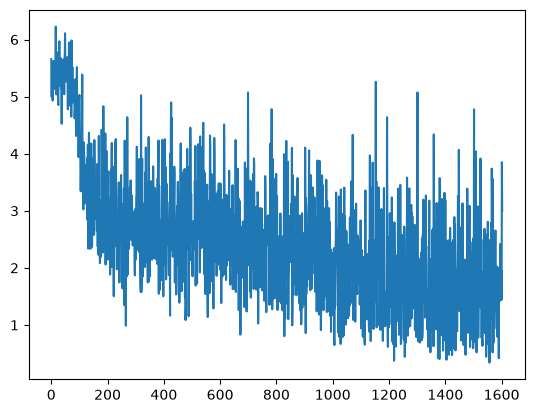

In [26]:
plt.plot(losses)

# 6.1 Prediction and the no-answer score

In [27]:
# lab_6.ipynb
def get_validation_features(tk, samples):
  # First, tokenize the text. We get the offsets and return overflowing sequences in
  # order to break up long sequences into multiple inputs. The offsets will help us
  # determine the original answer text
  batch = tk(
        [[q,c] for q,c in zip(samples['question'], samples['context'])],
        padding='max_length',
        truncation='only_second',
        stride=128,
        return_overflowing_tokens=True,
        return_offsets_mapping=True
    )

  # We'll store the ID of the samples to calculate squad score
  batch['example_id'] = []
  # The overflow sample map tells us which input each sample corresponds to
  sample_map = batch.pop('overflow_to_sample_mapping')

  for i in range(len(batch['input_ids'])):
    # The sample index tells us which of the values in "samples" these features belong to
    sample_idx = sample_map[i]
    sequence_ids = batch.sequence_ids(i)

    # Add the ID to map these features back to the correct sample
    batch['example_id'].append(samples['id'][sample_idx])

    #Set offsets for non-context words to be None for ease of processing
    batch['offset_mapping'][i] = [o if sequence_ids[k] == 1 else None for k,o in enumerate(batch['offset_mapping'][i])]

  return batch

def val_collate_fn(inputs):
  input_ids = torch.tensor([i['input_ids'] for i in inputs])
  attention_mask = torch.tensor([i['attention_mask'] for i in inputs])

  # Truncate to max length
  max_len = max(attention_mask.sum(-1))
  input_ids = input_ids[:,:max_len]
  attention_mask = attention_mask[:,:max_len]

  return {'input_ids': input_ids, 'attention_mask': attention_mask}

In [28]:
# lab_6.ipynb
validation_dataset = qa_datasets['validation'].map(partial(get_validation_features, tokenizer), batched=True, remove_columns=qa_datasets['validation'].column_names)

In [29]:
# lab_6.ipynb
def predict(model: nn.Module, valid_dl: DataLoader):
  """
  Evaluates the model on the given dataset
  :param model: The model under evaluation
  :param valid_dl: A `DataLoader` reading validation data
  :return: The accuracy of the model on the dataset
  """
  # VERY IMPORTANT: Put your model in "eval" mode -- this disables things like
  # layer normalization and dropout
  model.eval()
  start_logits_all = []
  end_logits_all = []

  # ALSO IMPORTANT: Don't accumulate gradients during this process
  with torch.no_grad():
    for batch in tqdm(valid_dl, desc='Evaluation'):
      batch = {b: batch[b].to(device) for b in batch}

      # Pass the inputs through the model, get the current loss and logits
      outputs = model(
          input_ids=batch['input_ids'],
          attention_mask=batch['attention_mask']
      )
      # Store the "start" class logits and "end" class logits for every token in the input
      start_logits_all.extend(list(outputs['start_logits'].detach().cpu().numpy()))
      end_logits_all.extend(list(outputs['end_logits'].detach().cpu().numpy()))


    return start_logits_all,end_logits_all

def post_process_predictions(examples, dataset, logits, num_possible_answers = 20, max_answer_length = 30):
  all_start_logits, all_end_logits = logits
  # Build a map from example to its corresponding features. This will allow us to index from
  # sample ID to all of the features for that sample (in case they were split up due to long input)
  example_id_to_index = {k: i for i, k in enumerate(examples["id"])}
  features_per_example = defaultdict(list)
  for i, feature in enumerate(dataset):
      features_per_example[example_id_to_index[feature["example_id"]]].append(i)

  # Create somewhere to store our predictions
  predictions = OrderedDict()

  # Iterate through each sample in the dataset
  for j, sample in enumerate(tqdm(examples)):

    # Get the feature indices (all of the features split across the batch)
    feature_indices = features_per_example[j]
    # Get the original context which predumably has the answer text
    context = sample['context']

    preds = []
    null_score = None
    # Iterate through all of the features
    for ft_idx in feature_indices:

      # Get the start and end answer logits for this input
      start_logits = all_start_logits[ft_idx]
      end_logits = all_end_logits[ft_idx]

      # Get the offsets to map token indices to character indices
      offset_mapping = dataset[ft_idx]['offset_mapping']

      if null_score is None or start_logits[0] + end_logits[0] < null_score:
        null_score = float(start_logits[0] + end_logits[0])

      # Sort the logits and take the top N
      start_indices = np.argsort(start_logits)[::-1][:num_possible_answers]
      end_indices = np.argsort(end_logits)[::-1][:num_possible_answers]

      # Iterate through start and end indices
      for start_index in start_indices:
        for end_index in end_indices:

          # Ignore this combination if either the indices are not in the context
          if start_index >= len(offset_mapping) or end_index >= len(offset_mapping) or offset_mapping[start_index] is None or offset_mapping[end_index] is None:
            continue

          # Also ignore if the start index is greater than the end index of the number of tokens
          # is greater than some specified threshold
          if start_index > end_index or end_index - start_index + 1 > max_answer_length:
            continue

          ans_text = context[offset_mapping[start_index][0]:offset_mapping[end_index][1]]
          preds.append({
              'score': float(start_logits[start_index] + end_logits[end_index]),  # changed: a plain float
              'text': ans_text,
              'start': offset_mapping[start_index][0]
          })

    if len(preds) > 0:
      # Sort by score to get the top answer
      answer = sorted(preds, key=lambda x: x['score'], reverse=True)[0]
    else:
      answer = {'score': 0.0, 'text': "", 'start': -1}

    answer['no_answer_score'] = null_score - answer['score']
    predictions[sample['id']] = answer
  return predictions

In [30]:
# lab_6.ipynb
val_dl = DataLoader(validation_dataset, collate_fn=val_collate_fn, batch_size=32)
logits = predict(model, val_dl)

Evaluation: 100%|██████████████████████████████████████████████████████████████████████| 37/37 [00:13<00:00,  2.77it/s]


In [31]:
# lab_6.ipynb
predictions = post_process_predictions(qa_datasets['validation'], validation_dataset, logits)

100%|████████████████████████████████████████████████████████████████████████████| 1155/1155 [00:00<00:00, 1334.48it/s]


# 6.1 No-answer threshold

In [32]:
# claude
def add_predictions(df, predictions):
    df = df.copy()
    df["qa_text"] = [predictions[str(index)]["text"] for index in df.index]
    df["qa_start"] = [predictions[str(index)]["start"] for index in df.index]
    df["no_answer_score"] = [predictions[str(index)]["no_answer_score"] for index in df.index]
    return df

def apply_threshold(df, threshold):
    df = df.copy()
    df["pred_qa"] = df["no_answer_score"] <= threshold
    df["pred_text"] = df["qa_text"].where(df["pred_qa"], "")
    return df

def choose_threshold(df):
    thresholds = np.sort(df["no_answer_score"].unique())
    macro_f1 = [precision_recall_fscore_support(df["answerable"], df["no_answer_score"] <= threshold, average="macro", zero_division=0)[2] for threshold in thresholds]
    return thresholds[np.argmax(macro_f1)]

In [33]:
# val
df_val = add_predictions(df_val, predictions)
no_answer_threshold = choose_threshold(df_val)
df_val = apply_threshold(df_val, no_answer_threshold)
print(f"no-answer threshold: {no_answer_threshold:.3f} (no answer when no_answer_score > threshold)")
df_val[["lang", "question", "answer", "pred_text", "no_answer_score"]].head(10)

no-answer threshold: -1.274 (no answer when no_answer_score > threshold)


,lang,question,answer,pred_text,no_answer_score
0,te,ఒరెగాన్ రాష్ట్రంలోని అతిపెద్ద నగరం ఏది ?,Portland,Portland,-9.445167
1,te,కలరా వ్యాధిని మొదటగా ఏ దేశంలో కనుగొన్నారు ?,Indian subcontinent,Indian subcontinent,-6.898298
2,te,కలరా వ్యాధిని మొదటగా ఏ దేశంలో కనుగొన్నారు ?,England,United States,-6.137985
3,te,మొదటి ప్రపంచ యుద్ధం ఎప్పుడు మొదలయింది ?,1914,1914 to 1918,-10.656258
4,te,మొదటి ప్రపంచ యుద్ధం ఎప్పుడు మొదలయింది ?,28 July 1914,28 July 1914,-11.391598
5,te,సమాచార చట్టం-2005 ను ఏ ప్రభుత్వం ఆమోదించింది?,India,Supreme Court of India,-3.301140
6,te,ప్రాచీన భారతదేశంలో ఎన్ని భాషలు వాడుకలో ఉండేవి?,122,122,-8.152836
7,te,మనిషిని సగటున ఉండాల్సిన రక్తం ఎంత?,approximately 5 liters,5 liters,-8.732328
8,te,టెక్సస్ రాష్ట్రంలోని అతిపెద్ద మానవ నిర్మితం ఏది ?,JPMorgan Chase Tower,Downtown Houston,-10.677456
9,te,భారతదేశంలో ఓటు హక్కు పొందడానికి ఉండవలసిన కనీస ...,18,21 years to 18 years,-2.748024


# 6.1 SQuAD-v2 exact match and token F1

In [34]:
# lab_6.ipynb
""" Official evaluation script for v1.1 of the SQuAD dataset. """
from __future__ import print_function
from collections import Counter
import string
import re
import argparse
import json
import sys


def normalize_answer(s):
    """Lower text and remove punctuation, articles and extra whitespace."""
    def remove_articles(text):
        return re.sub(r'\b(a|an|the)\b', ' ', text)

    def white_space_fix(text):
        return ' '.join(text.split())

    def remove_punc(text):
        exclude = set(string.punctuation)
        return ''.join(ch for ch in text if ch not in exclude)

    def lower(text):
        return text.lower()

    return white_space_fix(remove_articles(remove_punc(lower(s))))


def f1_score(prediction, ground_truth):
    prediction_tokens = normalize_answer(prediction).split()
    ground_truth_tokens = normalize_answer(ground_truth).split()
    common = Counter(prediction_tokens) & Counter(ground_truth_tokens)
    num_same = sum(common.values())
    if num_same == 0:
        return 0
    precision = 1.0 * num_same / len(prediction_tokens)
    recall = 1.0 * num_same / len(ground_truth_tokens)
    f1 = (2 * precision * recall) / (precision + recall)
    return f1


def exact_match_score(prediction, ground_truth):
    return (normalize_answer(prediction) == normalize_answer(ground_truth))


def metric_max_over_ground_truths(metric_fn, prediction, ground_truths):
    scores_for_ground_truths = []
    for ground_truth in ground_truths:
        score = metric_fn(prediction, ground_truth)
        scores_for_ground_truths.append(score)
    return max(scores_for_ground_truths)


def evaluate_squad(dataset, predictions):
    f1 = exact_match = total = 0
    for article in dataset:
        for paragraph in article['paragraphs']:
            for qa in paragraph['qas']:
                total += 1
                if qa['id'] not in predictions:
                    message = 'Unanswered question ' + qa['id'] + \
                              ' will receive score 0.'
                    print(message, file=sys.stderr)
                    continue
                ground_truths = list(map(lambda x: x['text'], qa['answers']))
                prediction = predictions[qa['id']]
                exact_match += metric_max_over_ground_truths(
                    exact_match_score, prediction, ground_truths)
                f1 += metric_max_over_ground_truths(
                    f1_score, prediction, ground_truths)

    exact_match = 100.0 * exact_match / total
    f1 = 100.0 * f1 / total

    return {'exact_match': exact_match, 'f1': f1}

def compute_squad(predictions, references):
  pred_dict = {prediction["id"]: prediction["prediction_text"] for prediction in predictions}
  dataset = [
      {
          "paragraphs": [
              {
                  "qas": [
                      {
                          "answers": [{"text": answer_text} for answer_text in ref["answers"]["text"]],
                          "id": ref["id"],
                      }
                      for ref in references
                  ]
              }
          ]
      }
  ]
  score = evaluate_squad(dataset=dataset, predictions=pred_dict)
  return score

In [35]:
# lab_6.ipynb
squad_metric = load_metric("squad_v2")

def compute_squad(*, references, predictions):
    return squad_metric.compute(references=references, predictions=predictions)

In [36]:
# claude
# the gold answers
def squad_answers(example):
    if example["answerable"]:
        return {"answers": {"text": [example["answer"]], "answer_start": [example["answer_start"]]}}
    return {"answers": {"text": [], "answer_start": []}}

qa_datasets["validation"] = qa_datasets["validation"].map(squad_answers)

In [37]:
# lab_6.ipynb
formatted_predictions = [{'id': str(k), 'prediction_text': v, 'no_answer_probability': 0.0} for k,v in df_val["pred_text"].items()]
gold = [{'id': example['id'], 'answers': example['answers']} for example in qa_datasets['validation']]

In [38]:
# lab_6.ipynb
compute_squad(references=gold, predictions=formatted_predictions)

{'exact': 47.18614718614719,
 'f1': 55.70817758891537,
 'total': 1155,
 'HasAns_exact': 47.426841574167504,
 'HasAns_f1': 57.35917771462891,
 'HasAns_total': 991,
 'NoAns_exact': 45.73170731707317,
 'NoAns_f1': 45.73170731707317,
 'NoAns_total': 164,
 'best_exact': 54.112554112554115,
 'best_exact_thresh': 0.0,
 'best_f1': 62.56532044605826,
 'best_f1_thresh': 0.0}

# 6.2 Evaluation

In [56]:
# claude
# lab_6.ipynb
def evaluate_qa(df, formatted_predictions, gold):
    rows = []
    for lang in ["all"] + LANGUAGES:
        part = df if lang == "all" else df[df["lang"] == lang]
        ids = {str(index) for index in part.index}
        scores = compute_squad(references=[g for g in gold if g['id'] in ids], predictions=[p for p in formatted_predictions if p['id'] in ids])
        rows.append({
            "lang": lang,
            "n": len(part),
            "n_unans": int((~part["answerable"]).sum()),
            "em": scores["exact"],
            "f1": scores["f1"],
            "em_ans": scores["HasAns_exact"],
            "f1_ans": scores["HasAns_f1"],
            "em_unans": scores["NoAns_exact"],
            "macro_f1": 100 * precision_recall_fscore_support(part["answerable"], part["pred_qa"], average="macro", zero_division=0)[2],
        })
    return pd.DataFrame(rows).round(1)

In [57]:
# val
display(evaluate_qa(df_val, formatted_predictions, gold))
display(evaluate_answerability(df_val, "pred_qa"))

,lang,n,n_unans,em,f1,em_ans,f1_ans,em_unans,macro_f1
0,all,1155,164,47.2,55.7,47.4,57.4,45.7,72.2
1,ar,415,52,52.5,59.4,46.6,54.5,94.2,84.0
2,ko,356,19,50.6,60.6,49.3,59.9,73.7,76.3
3,te,384,93,38.3,47.1,46.4,58.0,12.9,54.7


,lang,n,n_unans,ans_p,ans_r,ans_f1,unans_p,unans_r,unans_f1,macro_f1,accuracy
0,all,1155,164,0.913,0.947,0.930,0.586,0.457,0.514,0.722,0.877
1,ar,415,52,0.991,0.909,0.948,0.598,0.942,0.731,0.840,0.913
2,ko,356,19,0.985,0.950,0.967,0.452,0.737,0.560,0.763,0.938
3,te,384,93,0.780,0.990,0.873,0.800,0.129,0.222,0.547,0.781


# Week 43: Individual Extensions
Each member must take primary responsibility for one distinct extension. State a falsifiable hypothesis before running it and compare the extension with the relevant core model under the same evaluation protocol. Suitable extensions include:

* calibrated abstention or an alternative no-answer thresholding method; (Tobias)

In [59]:
# claude
half_a = df_val.sample(frac=0.5, random_state=42).index
df_val["fold"] = ["a" if index in half_a else "b" for index in df_val.index]
pd.crosstab(df_val["lang"], [df_val["fold"], df_val["answerable"]])

fold           a           b      
answerable False True  False True 
lang                              
ar            28   172    24   191
ko            12   183     7   154
te            38   145    55   146

In [60]:
# claude
# joint: one threshold for all languages (as in week 40-41); per language: one threshold per language
# every threshold is chosen with choose_threshold on the other half of the validation split
def cross_fit_thresholds(df, per_language):
    df = df.copy()
    df["threshold"] = 0.0
    for fold in ["a", "b"]:
        tune = df[df["fold"] != fold]
        for lang in LANGUAGES:
            if per_language:
                threshold = choose_threshold(tune[tune["lang"] == lang])
            else:
                threshold = choose_threshold(tune)
            df.loc[(df["fold"] == fold) & (df["lang"] == lang), "threshold"] = threshold
    return apply_threshold(df, df["threshold"])

In [61]:
# claude
def compare_thresholds(df, seed):
    rows = []
    for method, per_language in [("joint", False), ("per language", True)]:
        df_method = cross_fit_thresholds(df, per_language)
        method_predictions = [{'id': str(k), 'prediction_text': v, 'no_answer_probability': 0.0} for k,v in df_method["pred_text"].items()]
        rows.append(evaluate_qa(df_method, method_predictions, gold).assign(seed=seed, method=method))
    return pd.concat(rows)

In [62]:
# val
df_joint = cross_fit_thresholds(df_val, per_language=False)
df_per_language = cross_fit_thresholds(df_val, per_language=True)
display(pd.DataFrame({"joint": df_joint.groupby(["fold", "lang"])["threshold"].first(),
                      "per language": df_per_language.groupby(["fold", "lang"])["threshold"].first()}).round(2))
display(evaluate_answerability(df_joint, "pred_qa"))
display(evaluate_answerability(df_per_language, "pred_qa"))

joint  per language
fold lang                     
a    ar    -0.40          0.24
     ko    -0.40         -0.53
     te    -0.40         -5.41
b    ar    -1.27          0.12
     ko    -1.27         -1.39
     te    -1.27         -5.82

,lang,n,n_unans,ans_p,ans_r,ans_f1,unans_p,unans_r,unans_f1,macro_f1,accuracy
0,all,1155,164,0.910,0.952,0.930,0.597,0.433,0.502,0.716,0.878
1,ar,415,52,0.988,0.920,0.953,0.623,0.923,0.744,0.849,0.920
2,ko,356,19,0.979,0.953,0.965,0.429,0.632,0.511,0.738,0.935
3,te,384,93,0.778,0.990,0.871,0.786,0.118,0.206,0.539,0.779


,lang,n,n_unans,ans_p,ans_r,ans_f1,unans_p,unans_r,unans_f1,macro_f1,accuracy
0,all,1155,164,0.931,0.897,0.914,0.490,0.598,0.538,0.726,0.855
1,ar,415,52,0.975,0.948,0.961,0.694,0.827,0.754,0.858,0.933
2,ko,356,19,0.982,0.950,0.965,0.433,0.684,0.531,0.748,0.935
3,te,384,93,0.815,0.773,0.794,0.389,0.452,0.418,0.606,0.695


In [63]:
# claude
# the items whose answer / no-answer decision changes: True = the new decision is correct
changed = df_per_language[df_joint["pred_qa"] != df_per_language["pred_qa"]]
pd.crosstab(changed["lang"], changed["pred_qa"] == changed["answerable"], margins=True)

col_0,False,True,All
lang,,,
ar,5,10,15
ko,1,1,2
te,63,31,94
All,69,42,111


### seed = [42, 43, 44]

In [64]:
# lab_6.ipynb
seed_scores = [compare_thresholds(df_val, 42)]
model.to('cpu')
for seed in [43, 44]:
    enforce_reproducibility(seed)
    seed_model = AutoModelForQuestionAnswering.from_pretrained("xlm-roberta-base").to(device)
    optimizer_grouped_parameters = [
        {'params': [p for n, p in seed_model.named_parameters() if not any(nd in n for nd in no_decay)],
          'weight_decay': weight_decay},
        {'params': [p for n, p in seed_model.named_parameters() if any(nd in n for nd in no_decay)], 'weight_decay': 0.0}
    ]
    optimizer = AdamW(optimizer_grouped_parameters, lr=lr)
    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        warmup_steps,
        n_epochs * len(train_dl)
    )
    losses = train(
        seed_model,
        train_dl,
        optimizer,
        scheduler,
        n_epochs,
        device
    )
    logits = predict(seed_model, val_dl)
    seed_predictions = post_process_predictions(qa_datasets['validation'], validation_dataset, logits)
    seed_model.to('cpu')
    df_seed = add_predictions(df_val, seed_predictions)
    seed_scores.append(compare_thresholds(df_seed, seed))

scores = pd.concat(seed_scores)
scores.groupby(["method", "lang"], sort=False)[["em", "f1", "macro_f1"]].agg(["mean", "std"]).round(1)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForQuestionAnswering LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
qa_outputs.weight           | MISSING    | 
qa_outputs.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
100%|████████████████████████████████████████████████████████████████████████████| 1155/1155 [00:00<00:00, 1312.78it/s]


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForQuestionAnswering LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
qa_outputs.weight           | MISSING    | 
qa_outputs.bias             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
100%|████████████████████████████████████████████████████████████████████████████| 1155/1155 [00:00<00:00, 1328.32it/s]


em         f1      macro_f1     
                   mean  std  mean  std     mean  std
method       lang                                    
joint        all   44.8  2.0  53.1  2.5     68.1  3.5
             ar    48.3  3.7  56.1  3.5     80.1  5.7
             ko    49.9  1.6  58.8  2.2     71.7  2.4
             te    36.3  1.5  44.6  2.0     51.6  2.0
per language all   45.7  2.0  53.1  2.6     69.1  3.6
             ar    48.0  2.9  56.0  3.1     80.7  6.0
             ko    50.0  1.0  58.9  1.8     70.9  3.6
             te    39.2  2.2  44.7  3.2     57.4  3.0

In [65]:
# claude
macro_f1 = scores.pivot_table(index=["seed", "lang"], columns="method", values="macro_f1", sort=False)
macro_f1["difference"] = macro_f1["per language"] - macro_f1["joint"]
macro_f1.round(1)

method     joint  per language  difference
seed lang                                 
42   all    71.6          72.6         1.0
     ar     84.9          85.8         0.9
     ko     73.8          74.8         1.0
     te     53.9          60.6         6.7
43   all    68.1          69.1         1.0
     ar     81.7          82.1         0.4
     ko     72.2          67.6        -4.6
     te     50.3          57.0         6.7
44   all    64.6          65.5         0.9
     ar     73.8          74.1         0.3
     ko     69.1          70.4         1.3
     te     50.7          54.6         3.9

In [66]:
# claude
# infra section in project description
print(f"torch {torch.__version__} | transformers {transformers.__version__} | device: {torch.cuda.get_device_name() if device.type == 'cuda' else 'cpu'}")
print(f"seeds: 42, 43, 44 | training examples: {len(qa_datasets['train'])} ({len(tokenized_dataset)} windows of at most {tokenizer.model_max_length} tokens, stride 128) | epochs: {n_epochs} | batch size: {train_dl.batch_size} | lr: {lr}")

torch 2.14.0+cu130 | transformers 5.16.1 | device: NVIDIA GeForce RTX 4070 Laptop GPU
seeds: 42, 43, 44 | training examples: 6335 (6411 windows of at most 512 tokens, stride 128) | epochs: 1 | batch size: 4 | lr: 2e-05
